<a href="https://colab.research.google.com/github/rustam4ike/classification_ru_news/blob/main/practice_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**КЛАССИФИКАЦИЯ НОВОСТНЫХ ЗАГОЛОВКОВ С ПОМОЩЬЮ BERT**

### ТЕОРИЯ И СХЕМЫ

КРАТКАЯ АННОТАЦИЯ

Сравнительное исследование методов классификации новостных заголовков на русском языке. Сопоставляются три подхода: fine-tuning предобученного трансформера RuBERT и две классические модели на TF-IDF-признаках — логистическая регрессия и линейный SVM. Задача — многоклассовая (10 тем), метрики — accuracy и weighted F1.

КРАТКОЕ ОПИСАНИЕ ПРОБЛЕМЫ

Дан датасет lenta-ru-news.csv с парами «заголовок → тема». Требуется построить классификатор, относящий заголовок к одной из 10 наиболее частых тем. Основные сложности:

Короткие тексты — средняя длина 14 токенов, мало контекста для различения тем.

Семантическое перекрытие — похожие классы описывают близкие области и часто путаются.

Дисбаланс классов — решается балансированной выборкой по 7000 примеров на класс.

ОСНОВНЫЕ КОНЦЕПЦИИ

TF-IDF (Term Frequency — Inverse Document Frequency) — мера важности слова в документе относительно корпуса. Слово тем важнее для документа, чем чаще оно в нём и чем реже встречается в других документах.

Логистическая регрессия — линейный классификатор, моделирующий вероятность класса через softmax от линейной комбинации признаков.

Linear SVM — линейный метод опорных векторов, ищущий гиперплоскость с максимальным зазором между классами.

Трансформер и BERT — нейросетевая архитектура на основе механизма self-attention, позволяющего учитывать контекст каждого токена относительно всех остальных. Предобучение на большом корпусе (masked language modeling) даёт универсальные языковые представления, которые затем дообучаются под конкретную задачу (fine-tuning).

RuBERT (DeepPavlov/rubert-base-cased) — русскоязычная версия BERT, обученная на русских текстах.

СХЕМА

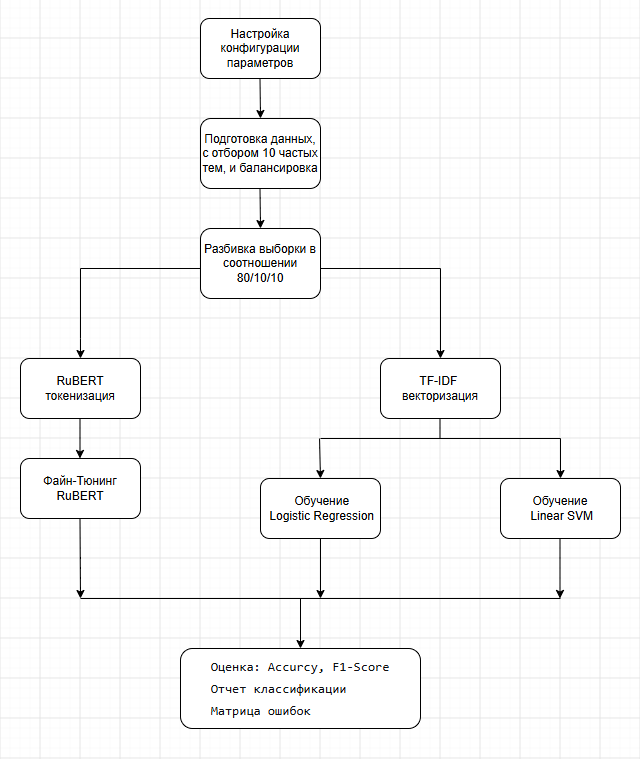

### СТЕК ТЕХНОЛОГИЙ

#### ЗАГРУЗКА ДАТАСЕТА

In [ ]:
!gdown "https://drive.google.com/uc?id=1oxrFDIfBCP3AXntVzQILkjzKTlc6PYhf"

In [ ]:
!unzip -qo "lenta-ru-news.csv.zip" -d ./

#### ИМПОРТ НЕОБХОДИМЫХ БИБЛИОТЕК

In [ ]:
import pandas as pd
import numpy as np
import re
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
# PyTorch и Transformers
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
# Для визуализации
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
sns.despine()
plt.rc("figure", autolayout=True)
plt.rc("axes", labelweight="bold", labelsize="large", titleweight="bold", titlepad=10)

#### ПОДГОТОВКА ДАННЫХ

In [ ]:
# ---ФИКСАЦИЯ СИДА---
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
# ---КОНФИГУРАЦИЯ---
DATA_PATH = "lenta-ru-news.csv"
MODEL_NAME = "DeepPavlov/rubert-base-cased"
SAMPLES_PER_CLASS = 7000
EPOCHS = 3
BATCH_SIZE = 32

In [ ]:
# ---ЗАГРУЗКА И ПОДГОТОВКА ДАННЫХ---
# Загрузка и удаление пропусков
df = pd.read_csv(DATA_PATH, usecols=['title', 'topic'])
df = df.dropna(subset=['title', 'topic'])

# Отбор 10 самых частых тем
top_10_topics = df['topic'].value_counts().head(10).index
df = df[df['topic'].isin(top_10_topics)].copy()

# Балансировка выборки
df = df.groupby('topic', group_keys=False).apply(
    lambda x: x.sample(min(len(x), SAMPLES_PER_CLASS), random_state=SEED)
).reset_index(drop=True)

# Функция чистки текста
def clean_text(text):
    text = str(text).strip()
    text = re.sub(r'\s+', ' ', text)

    return text

# Применяем чистку
df['title'] = df['title'].apply(clean_text)
df['topic'] = df['topic'].apply(clean_text)

print(df['topic'].value_counts())
print(df.head())

/tmp/ipykernel_1425/1121591429.py:3: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH, usecols=['title', 'topic'])
/tmp/ipykernel_1425/1121591429.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('topic', group_keys=False).apply(


topic
Бывший СССР        7000
Дом                7000
Из жизни           7000
Интернет и СМИ     7000
Культура           7000
Мир                7000
Наука и техника    7000
Россия             7000
Спорт              7000
Экономика          7000
Name: count, dtype: int64
                                               title        topic
0  "Газпром": Украина увеличила отбор экспортного...  Бывший СССР
1  Назарбаев пообещал безработным дополнительную ...  Бывший СССР
2    Торгующих с Россией украинцев предложили сажать  Бывший СССР
3  Обидевшей крымских татар книгой заинтересовала...  Бывший СССР
4  На Украине задержали грузовик с человеческими ...  Бывший СССР


In [ ]:
# ---РАЗБИВКА ВЫБОРОК--
X = df['title']
y = df['topic']

# Отделяем 80% на train и 20% на временную выборку
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Делим оставшиеся 20% поровну
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print(f"Тренировочная выборка: {X_train.shape[0]}")
print(f"Проверочная выборка: {X_valid.shape[0]}")
print(f"Тестовая выборка: {X_test.shape[0]}")

# Кодируем метки
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_valid = le.transform(y_valid)
y_test = le.transform(y_test)

num_labels = len(le.classes_)
print(f"Количество классов: {num_labels}")

Тренировочная выборка: 56000
Проверочная выборка: 7000
Тестовая выборка: 7000
Количество классов: 10


#### РЕАЛИЗАЦИЯ МОДЕЛИ

In [ ]:
# ---ПОДГОТОВКА ДАННЫХ ДЛЯ BERT---
# Загрузка токенизатора
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [ ]:
# Функция токенизации
def tokenize_function(texts):
    return tokenizer(
        texts,
        truncation=True,
        max_length=32, # 32 достаточно (максимальная длина в title 27 токенов)
        return_tensors=None  # Возвращаем списки, а не тензоры
    )

# Токенизируем все данные
train_encodings = tokenize_function(X_train.tolist())
valid_encodings = tokenize_function(X_valid.tolist())
test_encodings = tokenize_function(X_test.tolist())

In [ ]:
# Класс датасета
class TextDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

# Создаем датасеты
train_dataset = TextDataset(train_encodings, y_train)
valid_dataset = TextDataset(valid_encodings, y_valid)
test_dataset = TextDataset(test_encodings, y_test)

In [ ]:
# Функция для вычисления метрик
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    acc = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, average='weighted')
    return {
        'accuracy': acc,
        'f1': f1
    }

In [ ]:
# ---НАСТРОЙКА ГИПЕРПАРАМЕТРОВ---
# Загружаем модель BERT для классификации
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels
)

In [ ]:
# Автоматический расчет общего числа шагов и шагов разогрева
steps_per_epoch = len(train_dataset) // BATCH_SIZE
total_training_steps = steps_per_epoch * EPOCHS
warmup_steps = int(total_training_steps * 0.1)  # 10% от общего числа шагов
print(f'Количество шагов для разогрева: {warmup_steps}')

# Параметры обучения
training_args = TrainingArguments(
    output_dir='./results',                     # Папка для сохранения результатов
    num_train_epochs=EPOCHS,                    # Количество эпох
    per_device_train_batch_size=BATCH_SIZE,     # Размер батча для обучения
    per_device_eval_batch_size=64,              # Размер батча на валидации
    learning_rate=2e-5,                         # Скорость обучения
    weight_decay=0.01,                          # L2-регуляризация
    warmup_steps=warmup_steps,                  # Шаги для плавного разогрева
    eval_strategy="epoch",                      # Валидация по эпохам
    save_strategy="epoch",                      # Сохранение чекпоинта
    load_best_model_at_end=True,                # Загрузка лучшей эпохи
    metric_for_best_model="f1",                 # Метрика лучшая модели
    fp16=torch.cuda.is_available()              # Ускоряет обучение на GPU
)

# Создаем коллатор для динамического паддинга батчей
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Создаем Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    compute_metrics=compute_metrics,
    data_collator=data_collator
)

Количество шагов для разогрева: 525


#### ОБУЧЕНИЕ

In [ ]:
# Запускаем обучение
print("Запускаем Файн-Тюнинг BERT...")
trainer.train()

Запускаем Файн-Тюнинг BERT...


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.611596,0.556625,0.820714,0.819449
2,0.428851,0.542261,0.827000,0.825524
3,0.281254,0.563576,0.832429,0.831480


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=5250, training_loss=0.5188945690336682, metrics={'train_runtime': 847.4365, 'train_samples_per_second': 198.245, 'train_steps_per_second': 6.195, 'total_flos': 1529541533124864.0, 'train_loss': 0.5188945690336682, 'epoch': 3.0})

In [ ]:
# Сохраняем модель и токенизатор
trainer.save_model('./rus_news_bert_model')
tokenizer.save_pretrained('./rus_news_bert_model')
print("Модель сохранена")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Модель сохранена


#### ОЦЕНКА РЕЗУЛЬТАТОВ

In [ ]:
# ---ФУНКЦИЯ ОЦЕНКИ И ВИЗУАЛИЗАЦИИ---
def evaluate_predictions(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f"\n=================== {name} ===================")
    print(f"Accuracy: {acc:.4f} | F1-Score (weighted): {f1:.4f}")
    print("\nОтчет классификации:")
    print(classification_report(y_true, y_pred, target_names=le.classes_))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=le.classes_,
        yticklabels=le.classes_
    )
    plt.title(f'Матрица ошибок — {name}')
    plt.xlabel('Предсказанный класс')
    plt.ylabel('Истинный класс')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


=================== RuBERT Base ===================
Accuracy: 0.8429 | F1-Score (weighted): 0.8421

Отчет классификации:
                 precision    recall  f1-score   support

    Бывший СССР       0.86      0.90      0.88       700
            Дом       0.90      0.92      0.91       700
       Из жизни       0.76      0.75      0.75       700
 Интернет и СМИ       0.80      0.80      0.80       700
       Культура       0.86      0.87      0.86       700
            Мир       0.79      0.77      0.78       700
Наука и техника       0.85      0.86      0.86       700
         Россия       0.78      0.74      0.76       700
          Спорт       0.94      0.97      0.95       700
      Экономика       0.86      0.85      0.85       700

       accuracy                           0.84      7000
      macro avg       0.84      0.84      0.84      7000
   weighted avg       0.84      0.84      0.84      7000



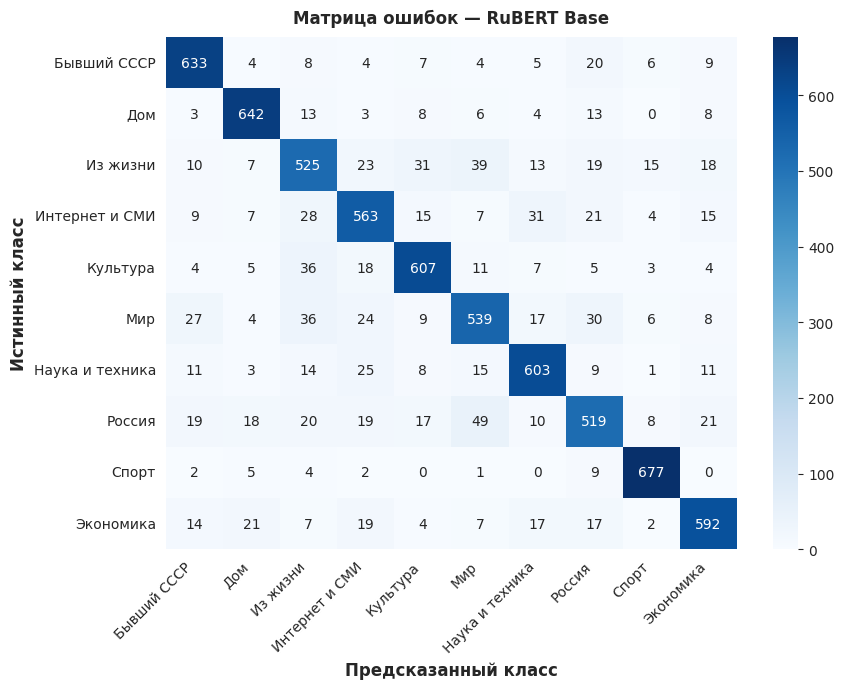

In [ ]:
# Тест для BERT
predictions_output = trainer.predict(test_dataset)
y_true_bert = predictions_output.label_ids
y_preds_bert = np.argmax(predictions_output.predictions, axis=1)
evaluate_predictions("RuBERT Base", y_true_bert, y_preds_bert)

#### СРАВНЕНИЕ С КЛАССИЧЕСКИМИ "ML"

In [ ]:
# ---TF-IDF ВЕКТОРИЗАЦИЯ---
vectorizer = TfidfVectorizer(
    max_features=50000, # максимальный размер словаря
    ngram_range=(1, 2), # устойчивые словосочетания
    sublinear_tf=True,  # сглаживает влияние частотных слов
    min_df=2            # борьба с шумом и переобучением
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
print("Векторизация текстов выполнена")

Векторизация текстов выполнена


In [ ]:
# ---ОБУЧЕНИЕ LOGISTIC REGRESSION---
log_reg = LogisticRegression(
    C=1.0,           # обратная сила регуляризации
    max_iter=1000,   # лимит итераций для гарантированной сходимости алгоритма
    solver='saga',   # оптимизатор, эффективный для больших разреженных данных (TF-IDF)
    random_state=SEED  # фиксация сида для воспроизводимости результатов
)
# Запуск обучения
log_reg.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000, n_jobs=-1, random_state=42, solver='saga')

In [ ]:
# ---ОБУЧЕНИЕ LINEAR SVM---
svm = LinearSVC(
    C=0.5,           # обратная сила регуляризации
    max_iter=2000,   # максимальное число шагов оптимизатора liblinear
    random_state=SEED  # фиксация сида для воспроизводимости результатов
)
# Запуск обучения
svm.fit(X_train_tfidf, y_train)

LinearSVC(C=0.5, max_iter=2000, random_state=42)


=================== Logistic Regression ===================
Accuracy: 0.7200 | F1-Score (weighted): 0.7211

Отчет классификации:
                 precision    recall  f1-score   support

    Бывший СССР       0.77      0.78      0.78       700
            Дом       0.82      0.80      0.81       700
       Из жизни       0.58      0.66      0.62       700
 Интернет и СМИ       0.73      0.66      0.69       700
       Культура       0.77      0.73      0.75       700
            Мир       0.62      0.60      0.61       700
Наука и техника       0.74      0.72      0.73       700
         Россия       0.59      0.61      0.60       700
          Спорт       0.92      0.88      0.90       700
      Экономика       0.70      0.75      0.73       700

       accuracy                           0.72      7000
      macro avg       0.72      0.72      0.72      7000
   weighted avg       0.72      0.72      0.72      7000



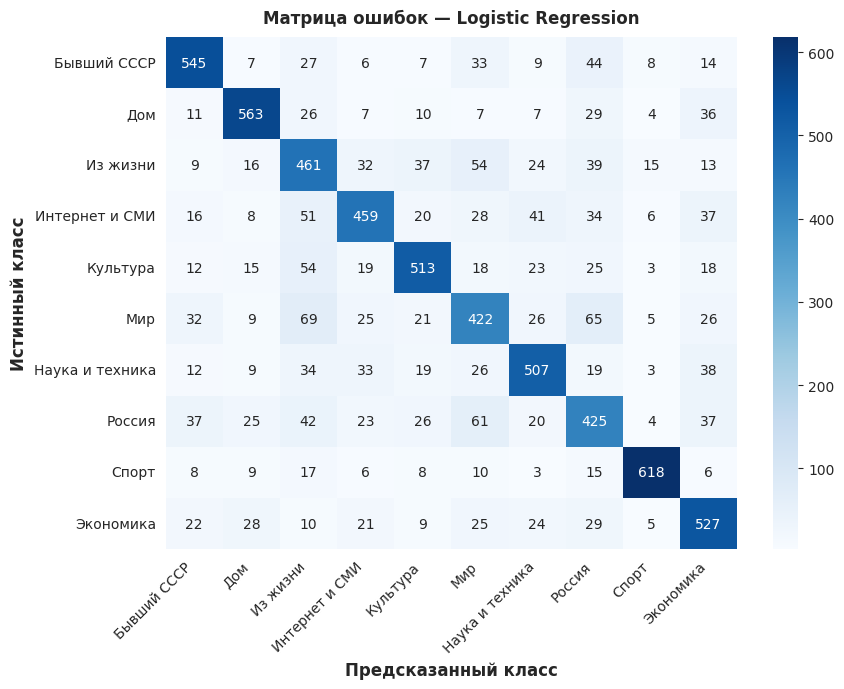

In [ ]:
# Тест для Logistic Regression
y_preds_log_reg = log_reg.predict(X_test_tfidf)
evaluate_predictions("Logistic Regression", y_test, y_preds_log_reg)


=================== Linear SVM ===================
Accuracy: 0.7339 | F1-Score (weighted): 0.7331

Отчет классификации:
                 precision    recall  f1-score   support

    Бывший СССР       0.78      0.83      0.80       700
            Дом       0.81      0.85      0.83       700
       Из жизни       0.61      0.63      0.62       700
 Интернет и СМИ       0.72      0.68      0.70       700
       Культура       0.78      0.75      0.76       700
            Мир       0.63      0.59      0.61       700
Наука и техника       0.75      0.74      0.74       700
         Россия       0.60      0.59      0.60       700
          Спорт       0.91      0.92      0.91       700
      Экономика       0.73      0.76      0.75       700

       accuracy                           0.73      7000
      macro avg       0.73      0.73      0.73      7000
   weighted avg       0.73      0.73      0.73      7000



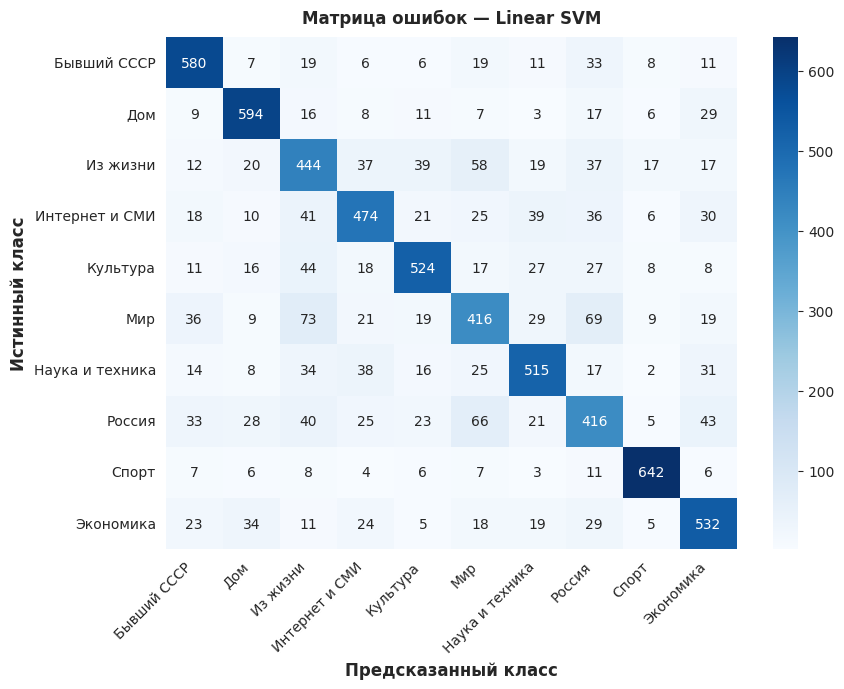

In [ ]:
# Тест для Linear SVM
y_preds_svm = svm.predict(X_test_tfidf)
evaluate_predictions("Linear SVM", y_test, y_preds_svm)

### ВЫВОДЫ

ОСНОВНЫЕ РЕЗУЛЬТАТЫ

**RuBERT**

Accuracy: 0.8429 | F1-Score: 0.8421

**Logistic Regression**

Accuracy: 0.7200 | F1-Score: 0.7211

**Linear SVM**

Accuracy: 0.7339 | F1-Score (weighted): 0.7331


BERT уверенно лидирует — отрыв от лучшей классической модели SVM 11 процентов. Это ожидаемо так как трансформер учитывает контекст, а TF-IDF видит только «мешок слов». SVM совсем чуть чуть обгоняет логистическую регрессию.

Спорт — лёгкий класс для всех моделей. Характерная лексика (гол, матч, чемпионат, название команды) однозначно маркирует тему. «Россия», «Мир», «Из жизни» — у всех моделей слабая сторона. Это подтверждает гипотезу о семантическом перекрытии классов: заголовки политических и «житейских» новостей используют общую лексику.

Разрыв между BERT и классикой максимален именно на «сложных» классах, то есть он выигрывает там, где нужен контекст, и сильно не превосходит классику там, где достаточно ключевых слов.

ПРОБЛЕМЫ И ОГРАНИЧЕНИЯ

Потолок BERT на этой задаче — 84–85%. Это не проблема кода и архетиктуры: модель уже обучена со всеми возможными параметрами. Дальнейший прирост возможен при испольлзовании другой модели, например rubert-large.

Семантическое перекрытие классов, о чем говорилось выше. Пары «Россия <-> Мир <-> Бывший СССР» и «Из жизни <-> Интернет и СМИ» путаются у всех трёх моделей. Это ограничение разметки, а не моделей: человек тоже часто не может однозначно отнести заголовок.

Короткие тексты. Средняя длина 14 токенов. В заголовке просто нет информации, чтобы различить близкие темы — BERT выжимает из контекста всё, что может, но потолок остаётся.

ВОЗМОЖНЫЕ УЛУЧШЕНИЯ

Как говорил выше можно попробовать применить другие модели русскоязычных BERT, и то предполагаю что прирост будет 1-3 процента.

Были идеи убрать "Россия" или "Мир", а можно и попробовать объеденить их. Но результат может поплыть в других тематиках. Поэтому оставляю как есть, и в любом случае вернусь к этой идеи.

В целом как итог хочу сказать что эксперимент методологически корректен и даёт интерпретируемый результат.

P.S.

Дополняю после основного вывода, коротко и по делу. Попробовал убрать "Мир", точность выросла на 2% на всех моделях, но в матрице ошибок так же худшие показания у темы "Россия", но теперь путается больше с другими классами.

Попробовал модели от ai-forever ruBert-base и ruBert-large, абсолютно никакой разницы не замечено.